# Import data and Correct the Time

In [207]:
import os
import pandas as pd

pmh=pd.read_csv("/Users/liuyunqian/Desktop/Duke/resume and rsearch stuff/research/stanford data/pmh.csv")
pmh.head()


,MRN,Noted_date,CodeType,Code,Desc10,CCS,DescCCS
0,98816154,2288-11-16T00:00:00Z,Dx10,M954,Acquired deformity of chest and rib,209.0,Other acquired deformities
1,98816154,2293-06-16T00:00:00Z,Dx10,F411,Generalized anxiety disorder,651.0,Anxiety disorders
2,98816154,2293-06-16T00:00:00Z,Dx10,F329,"Major depressive disorder, single episode, uns...",657.0,Mood disorders
3,98816163,2252-04-19T00:00:00Z,Dx10,R7989,Other specified abnormal findings of blood che...,258.0,Other screening for suspected conditions (not ...
4,98816163,2252-04-30T00:00:00Z,Dx10,C8590,"Non-Hodgkin lymphoma, unspecified, unspecified...",38.0,Non-Hodgkin`s lymphoma


In [208]:
# 假设 visits 是你的 DataFrame
time_cols = ["Noted_date"]

for col in time_cols:
    # 提取年份（跳过 NaN）
    year = (
        pmh[col].str.extract(r"(\d{4})")[0]
        .dropna()
        .astype(int) - 500
    )
    
    # 替换年份并保持其他部分不变
    decrypted_time = (
        year.astype(str) + 
        pmh[col].str[4:]
    )
    
    # 转换为 datetime（明确指定 ISO 8601 格式）
    pmh[f"{col}_500"] = pd.to_datetime(
        decrypted_time,
        format="%Y-%m-%dT%H:%M:%SZ",  # 明确指定格式
        errors="coerce"  # 无效时间转为 NaT
    )

# 查看结果
pmh

,MRN,Noted_date,CodeType,Code,Desc10,CCS,DescCCS,Noted_date_500
0,98816154,2288-11-16T00:00:00Z,Dx10,M954,Acquired deformity of chest and rib,209.0,Other acquired deformities,1788-11-16
1,98816154,2293-06-16T00:00:00Z,Dx10,F411,Generalized anxiety disorder,651.0,Anxiety disorders,1793-06-16
2,98816154,2293-06-16T00:00:00Z,Dx10,F329,"Major depressive disorder, single episode, uns...",657.0,Mood disorders,1793-06-16
3,98816163,2252-04-19T00:00:00Z,Dx10,R7989,Other specified abnormal findings of blood che...,258.0,Other screening for suspected conditions (not ...,1752-04-19
4,98816163,2252-04-30T00:00:00Z,Dx10,C8590,"Non-Hodgkin lymphoma, unspecified, unspecified...",38.0,Non-Hodgkin`s lymphoma,1752-04-30
...,...,...,...,...,...,...,...,...
755336,99999964,2229-04-27T00:00:00Z,Dx10,R519,NaN,NaN,NaN,1729-04-27
755337,99999964,2229-06-22T00:00:00Z,Dx10,K631,Perforation of intestine (nontraumatic),155.0,Other gastrointestinal disorders,1729-06-22
755338,99999976,2233-11-25T00:00:00Z,Dx10,D509,"Iron deficiency anemia, unspecified",59.0,Deficiency and other anemia,1733-11-25
755339,99999976,2233-11-25T00:00:00Z,Dx10,R591,Generalized enlarged lymph nodes,247.0,Lymphadenitis,1733-11-25


In [209]:
visits=pd.read_csv("/Users/liuyunqian/Desktop/Duke/resume and rsearch stuff/research/stanford data/visits.csv")
visits.head()


,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,Payor_class,Admit_service,Dx_ICD9,Dx_ICD10,Dx_name,Arrival_time,Roomed_time,Dispo_time,Admit_time,Departure_time
0,98880961,98874959,1,1,82,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,Medicare,Medicine,873.20,S01.21XA,"Laceration of nose, initial encounter",2283-03-02T07:36:59Z,2283-03-02T07:36:59Z,2283-03-02T12:29:59Z,2283-03-02T12:29:59Z,2283-03-02T13:44:59Z
1,99121566,99354408,1,2,59,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,NaN,Emergency Medicine,780.97,R41.82,"Altered mental status, unspecified altered men...",2239-08-22T01:13:51Z,2239-08-22T01:16:51Z,2239-08-22T07:20:51Z,2239-08-22T07:20:51Z,2239-08-22T10:45:51Z
2,99121566,99121037,2,2,63,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,NaN,Critical Care,"038.9, 785.52, 995.92","A41.9, R65.21",Septic shock (CMS-HCC),2240-03-11T03:06:51Z,2240-03-11T03:43:51Z,2240-03-11T08:31:51Z,2240-03-11T08:31:51Z,2240-03-11T13:37:51Z
3,99608739,99327434,1,2,90,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,Medicare,NaN,729.81,M79.89,Leg swelling,2296-08-31T16:43:05Z,2296-08-31T17:56:05Z,2296-08-31T20:56:05Z,NaN,2296-08-31T21:06:05Z
4,99608739,99502864,2,2,89,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,Medicare,NaN,788.20,R33.9,Urinary retention,2297-06-07T05:08:05Z,2297-06-07T05:59:05Z,2297-06-07T08:55:05Z,NaN,2297-06-07T09:35:05Z


In [210]:
import pandas as pd

# 假设 visits 是你的 DataFrame
time_cols = ["Arrival_time", "Roomed_time", "Departure_time", "Dispo_time", "Admit_time"]

for col in time_cols:
    # 提取年份（跳过 NaN）
    year = (
        visits[col].str.extract(r"(\d{4})")[0]
        .dropna()
        .astype(int) - 500
    )
    
    # 替换年份并保持其他部分不变
    decrypted_time = (
        year.astype(str) + 
        visits[col].str[4:]
    )
    
    # 转换为 datetime（明确指定 ISO 8601 格式）
    visits[f"{col}_500"] = pd.to_datetime(
        decrypted_time,
        format="%Y-%m-%dT%H:%M:%SZ",  # 明确指定格式
        errors="coerce"  # 无效时间转为 NaT
    )

# 查看结果
visits

,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,Arrival_time,Roomed_time,Dispo_time,Admit_time,Departure_time,Arrival_time_500,Roomed_time_500,Departure_time_500,Dispo_time_500,Admit_time_500
0,98880961,98874959,1,1,82,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,2283-03-02T07:36:59Z,2283-03-02T07:36:59Z,2283-03-02T12:29:59Z,2283-03-02T12:29:59Z,2283-03-02T13:44:59Z,1783-03-02 07:36:59,1783-03-02 07:36:59,1783-03-02 13:44:59,1783-03-02 12:29:59,1783-03-02 12:29:59
1,99121566,99354408,1,2,59,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,2239-08-22T01:13:51Z,2239-08-22T01:16:51Z,2239-08-22T07:20:51Z,2239-08-22T07:20:51Z,2239-08-22T10:45:51Z,1739-08-22 01:13:51,1739-08-22 01:16:51,1739-08-22 10:45:51,1739-08-22 07:20:51,1739-08-22 07:20:51
2,99121566,99121037,2,2,63,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,2240-03-11T03:06:51Z,2240-03-11T03:43:51Z,2240-03-11T08:31:51Z,2240-03-11T08:31:51Z,2240-03-11T13:37:51Z,1740-03-11 03:06:51,1740-03-11 03:43:51,1740-03-11 13:37:51,1740-03-11 08:31:51,1740-03-11 08:31:51
3,99608739,99327434,1,2,90,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,2296-08-31T16:43:05Z,2296-08-31T17:56:05Z,2296-08-31T20:56:05Z,NaN,2296-08-31T21:06:05Z,1796-08-31 16:43:05,1796-08-31 17:56:05,1796-08-31 21:06:05,1796-08-31 20:56:05,NaT
4,99608739,99502864,2,2,89,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,2297-06-07T05:08:05Z,2297-06-07T05:59:05Z,2297-06-07T08:55:05Z,NaN,2297-06-07T09:35:05Z,1797-06-07 05:08:05,1797-06-07 05:59:05,1797-06-07 09:35:05,1797-06-07 08:55:05,NaT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118380,99648524,99789968,3,5,41,F,Other,Non-Hispanic/Non-Latino,Self,36.8,...,2222-09-23T02:03:34Z,2222-09-23T02:58:34Z,2222-09-23T05:46:34Z,NaN,2222-09-23T06:38:34Z,1722-09-23 02:03:34,1722-09-23 02:58:34,1722-09-23 06:38:34,1722-09-23 05:46:34,NaT
118381,99312340,99391376,1,1,37,M,Black or African American,Non-Hispanic/Non-Latino,EMS,36.9,...,2245-12-31T02:58:40Z,2245-12-31T03:52:40Z,2245-12-31T05:10:40Z,2245-12-31T05:10:40Z,2245-12-31T06:30:40Z,1745-12-31 02:58:40,1745-12-31 03:52:40,1745-12-31 06:30:40,1745-12-31 05:10:40,1745-12-31 05:10:40
118382,99828357,99836129,1,1,22,M,Other,Hispanic/Latino,EMS,36.8,...,2234-09-07T02:27:43Z,2234-09-07T04:27:43Z,2234-09-07T05:04:43Z,NaN,2234-09-07T06:22:43Z,1734-09-07 02:27:43,1734-09-07 04:27:43,1734-09-07 06:22:43,1734-09-07 05:04:43,NaT
118383,98964925,98979879,1,1,24,M,Other,Hispanic/Latino,EMS,NaN,...,2288-11-06T10:18:50Z,2288-11-06T11:22:50Z,2288-11-06T13:11:50Z,NaN,2288-11-06T14:19:50Z,1788-11-06 10:18:50,1788-11-06 11:22:50,1788-11-06 14:19:50,1788-11-06 13:11:50,NaT


In [211]:
####把MRN变成字符串

visits['MRN'] = visits['MRN'].astype(str)
pmh['MRN'] = pmh['MRN'].astype(str)

print(visits.dtypes)           # 查看所有列的数据类型
   


MRN                               object
CSN                                int64
Visit_no                           int64
Visits                             int64
Age                                int64
Gender                            object
Race                              object
Ethnicity                         object
Means_of_arrival                  object
Triage_Temp                      float64
Triage_HR                        float64
Triage_RR                        float64
Triage_SpO2                      float64
Triage_SBP                       float64
Triage_DBP                       float64
Triage_acuity                     object
CC                                object
ED_dispo                          object
Hours_to_next_visit              float64
Dispo_class_next_visit            object
ED_LOS                           float64
Hosp_LOS                         float64
DC_dispo                          object
Payor_class                       object
Admit_service   

In [212]:
pmh["Noted_date_500"] = pd.to_datetime(pmh["Noted_date_500"])
print(pmh.dtypes) 

MRN                       object
Noted_date                object
CodeType                  object
Code                      object
Desc10                    object
CCS                      float64
DescCCS                   object
Noted_date_500    datetime64[ns]
dtype: object


# 疾病 outcome variable clean

### 1. convert all the diagnosis code into ICD10 and ICD9

In [213]:
from icd9to10_dict import icd9to10dict
def convert_9to10(code):
    if code in icd9to10dict.keys():
        return icd9to10dict[code]
    else:
        return code


In [214]:

pmh_df = pmh.copy()

# 新建一个版本列
pmh_df['icd_version'] = pmh_df['CodeType'].apply(lambda x: 9 if 'Dx9' in x else 10)

# 如果是 ICD-9，就转 ICD-10
pmh_df['ICD_10_Code'] = pmh_df.apply(
    lambda row: convert_9to10(row['Code']) if row['icd_version'] == 9 else row['Code'],
    axis=1
)

# 转换后版本统一设成 ICD-10
pmh_df['icd_version'] = 10

# 看看效果
pmh_df.head()

,MRN,Noted_date,CodeType,Code,Desc10,CCS,DescCCS,Noted_date_500,icd_version,ICD_10_Code
0,98816154,2288-11-16T00:00:00Z,Dx10,M954,Acquired deformity of chest and rib,209.0,Other acquired deformities,1788-11-16,10,M954
1,98816154,2293-06-16T00:00:00Z,Dx10,F411,Generalized anxiety disorder,651.0,Anxiety disorders,1793-06-16,10,F411
2,98816154,2293-06-16T00:00:00Z,Dx10,F329,"Major depressive disorder, single episode, uns...",657.0,Mood disorders,1793-06-16,10,F329
3,98816163,2252-04-19T00:00:00Z,Dx10,R7989,Other specified abnormal findings of blood che...,258.0,Other screening for suspected conditions (not ...,1752-04-19,10,R7989
4,98816163,2252-04-30T00:00:00Z,Dx10,C8590,"Non-Hodgkin lymphoma, unspecified, unspecified...",38.0,Non-Hodgkin`s lymphoma,1752-04-30,10,C8590


In [215]:
from icd10to9_dict import icd10to9dict

def convert_10to9(code, digit3=False):
    if code in icd10to9dict.keys():
        output = icd10to9dict[code]
    else:
        output = code
    if digit3:
        output = output[:3]
    return output
# 在 pmh_df 上生成 ICD_9_Code 列
pmh_df["ICD_9_Code"] = pmh_df.apply(
    lambda row: convert_10to9(row["ICD_10_Code"]), axis=1
)

pmh_df.head()

,MRN,Noted_date,CodeType,Code,Desc10,CCS,DescCCS,Noted_date_500,icd_version,ICD_10_Code,ICD_9_Code
0,98816154,2288-11-16T00:00:00Z,Dx10,M954,Acquired deformity of chest and rib,209.0,Other acquired deformities,1788-11-16,10,M954,7383
1,98816154,2293-06-16T00:00:00Z,Dx10,F411,Generalized anxiety disorder,651.0,Anxiety disorders,1793-06-16,10,F411,30002
2,98816154,2293-06-16T00:00:00Z,Dx10,F329,"Major depressive disorder, single episode, uns...",657.0,Mood disorders,1793-06-16,10,F329,311
3,98816163,2252-04-19T00:00:00Z,Dx10,R7989,Other specified abnormal findings of blood che...,258.0,Other screening for suspected conditions (not ...,1752-04-19,10,R7989,79099
4,98816163,2252-04-30T00:00:00Z,Dx10,C8590,"Non-Hodgkin lymphoma, unspecified, unspecified...",38.0,Non-Hodgkin`s lymphoma,1752-04-30,10,C8590,20280


### 2. For each visit we determine if this is any outcome that we are interested in

In [ ]:
###### Disease Dictionary

## "delete all "." as there are no "." in the database"
DISEASE_DEFS = {
    "sepsis": {
        "codes": ['99591', '99592', 
                  '67024', 'A419', 'R6520', 
                  'A4189', 'R6521', 'O0387', 
                  'T8144XA', 'O0337', 'O0487', 
                  'A4150', 'A410', 'A411', 'A412',
                    'A403', 'A414', 'A4151', 'A4152'],
        "keywords": ['sepsis']
    },
    "copd_exac": {
        "codes": ["J441", "J440", "49121", "49122"],
        "keywords": []
    },
    "acs_mi": {
        "codes": ["I200", "I210", "I211", "I212", "I213", "I214", "I219", "I220", "I221", "I222", "I228", "I229", "I230", "I231", "I232", "I233", "I234", "I235", "I236", "I237", "I240", "I241", "I248", "I249", "410", "4100", "4101", "4102", "4103", "4104", "4105", "4106", "4107", "4108", "4109", "4110", "4111", "41181", "41189"],
        "keywords": []
    },
    "stroke": {
        "codes": ["I60", "I61", "I62", "I63", "I64", "I65", "I66", "G45", "Z8673", "430", "431", "432", "43301", "43401", "43411", "436", "435", "V1254"],
        "keywords": ['stroke']
    },
    "ards": {
        "codes": ["J80", "J800", "51882"],
        "keywords": ['acute respiratory distress syndrome']
    },
    "aki": {
        "codes": ["N179", "N17","5849"],
        "keywords": ['acute kidney']
    },
    "pe": {
        "codes": ["I26", "I260", "I269", "41511", "41519"],
        "keywords": ['pulmonary embolism']
    },
    "pneumonia_bacterial": {
        "codes": ['J13', 'J14', 'J15', 'J150', 'J151', 'J152', 'J153', 'J154', 'J155', 'J156', 'J157', 'J158', 'J159'],
        "keywords": ['bacterial pneumonia']
    },
    "pneumonia_viral": {
        "codes": ['J09', 'J10', 'J11', 'J12', 'J120', 'J121', 'J122', 'J123', 'J128', 'J129'],
        "keywords": ['viral pneumonia']
    },
    "pneumonia_all": {
        "codes": ['J13', 'J14', 'J15', 'J150', 'J151', 'J152', 'J153', 'J154', 'J155', 'J156', 'J157', 'J158', 'J159','J09', 'J10', 'J11', 'J12', 'J120', 'J121', 'J122', 'J123', 'J128', 'J129'],
        "keywords": ['viral pneumonia', 'bacterial pneumonia']
    },
    "asthma_acute_exac": {
        "codes": ['J45901', 'J4521', 'J4531', 'J4541', 'J4551', '49392', '49301', '49302', '49311', '49312'],
        "keywords": []
    },
    "ahf": {
        "codes": ['I5021', 'I5023', 'I5031', 'I5033', 'I5041', 'I5043', 'I50811', 'I509', '42821', '42823', '42831', '42833', '42841', '42843', '4280'],
        "keywords": ['acute.*heart.*failure']
    }
    }



In [188]:
visits

,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,Arrival_time,Roomed_time,Dispo_time,Admit_time,Departure_time,Arrival_time_500,Roomed_time_500,Departure_time_500,Dispo_time_500,Admit_time_500
0,98880961,98874959,1,1,82,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,2283-03-02T07:36:59Z,2283-03-02T07:36:59Z,2283-03-02T12:29:59Z,2283-03-02T12:29:59Z,2283-03-02T13:44:59Z,1783-03-02 07:36:59,1783-03-02 07:36:59,1783-03-02 13:44:59,1783-03-02 12:29:59,1783-03-02 12:29:59
1,99121566,99354408,1,2,59,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,2239-08-22T01:13:51Z,2239-08-22T01:16:51Z,2239-08-22T07:20:51Z,2239-08-22T07:20:51Z,2239-08-22T10:45:51Z,1739-08-22 01:13:51,1739-08-22 01:16:51,1739-08-22 10:45:51,1739-08-22 07:20:51,1739-08-22 07:20:51
2,99121566,99121037,2,2,63,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,2240-03-11T03:06:51Z,2240-03-11T03:43:51Z,2240-03-11T08:31:51Z,2240-03-11T08:31:51Z,2240-03-11T13:37:51Z,1740-03-11 03:06:51,1740-03-11 03:43:51,1740-03-11 13:37:51,1740-03-11 08:31:51,1740-03-11 08:31:51
3,99608739,99327434,1,2,90,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,2296-08-31T16:43:05Z,2296-08-31T17:56:05Z,2296-08-31T20:56:05Z,NaN,2296-08-31T21:06:05Z,1796-08-31 16:43:05,1796-08-31 17:56:05,1796-08-31 21:06:05,1796-08-31 20:56:05,NaT
4,99608739,99502864,2,2,89,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,2297-06-07T05:08:05Z,2297-06-07T05:59:05Z,2297-06-07T08:55:05Z,NaN,2297-06-07T09:35:05Z,1797-06-07 05:08:05,1797-06-07 05:59:05,1797-06-07 09:35:05,1797-06-07 08:55:05,NaT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118380,99648524,99789968,3,5,41,F,Other,Non-Hispanic/Non-Latino,Self,36.8,...,2222-09-23T02:03:34Z,2222-09-23T02:58:34Z,2222-09-23T05:46:34Z,NaN,2222-09-23T06:38:34Z,1722-09-23 02:03:34,1722-09-23 02:58:34,1722-09-23 06:38:34,1722-09-23 05:46:34,NaT
118381,99312340,99391376,1,1,37,M,Black or African American,Non-Hispanic/Non-Latino,EMS,36.9,...,2245-12-31T02:58:40Z,2245-12-31T03:52:40Z,2245-12-31T05:10:40Z,2245-12-31T05:10:40Z,2245-12-31T06:30:40Z,1745-12-31 02:58:40,1745-12-31 03:52:40,1745-12-31 06:30:40,1745-12-31 05:10:40,1745-12-31 05:10:40
118382,99828357,99836129,1,1,22,M,Other,Hispanic/Latino,EMS,36.8,...,2234-09-07T02:27:43Z,2234-09-07T04:27:43Z,2234-09-07T05:04:43Z,NaN,2234-09-07T06:22:43Z,1734-09-07 02:27:43,1734-09-07 04:27:43,1734-09-07 06:22:43,1734-09-07 05:04:43,NaT
118383,98964925,98979879,1,1,24,M,Other,Hispanic/Latino,EMS,NaN,...,2288-11-06T10:18:50Z,2288-11-06T11:22:50Z,2288-11-06T13:11:50Z,NaN,2288-11-06T14:19:50Z,1788-11-06 10:18:50,1788-11-06 11:22:50,1788-11-06 14:19:50,1788-11-06 13:11:50,NaT


In [216]:
import re

def split_clean_icd(cell):
    """把一个格子里的 ICD 串拆成列表，去点、去空格、大写"""
    if pd.isna(cell):
        return []
    parts = re.split(r'[,\s;]+', str(cell))
    return [p.replace('.', '').strip().upper() for p in parts if p.strip()]

# 
visits_df = visits.copy()

# 新列：ICD9 / ICD10 拆成列表
visits_df['Dx_ICD9_list']  = visits_df['Dx_ICD9'].apply(split_clean_icd)
visits_df['Dx_ICD10_list'] = visits_df['Dx_ICD10'].apply(split_clean_icd)
visits_df

,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,Dispo_time,Admit_time,Departure_time,Arrival_time_500,Roomed_time_500,Departure_time_500,Dispo_time_500,Admit_time_500,Dx_ICD9_list,Dx_ICD10_list
0,98880961,98874959,1,1,82,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,2283-03-02T12:29:59Z,2283-03-02T12:29:59Z,2283-03-02T13:44:59Z,1783-03-02 07:36:59,1783-03-02 07:36:59,1783-03-02 13:44:59,1783-03-02 12:29:59,1783-03-02 12:29:59,[87320],[S0121XA]
1,99121566,99354408,1,2,59,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,2239-08-22T07:20:51Z,2239-08-22T07:20:51Z,2239-08-22T10:45:51Z,1739-08-22 01:13:51,1739-08-22 01:16:51,1739-08-22 10:45:51,1739-08-22 07:20:51,1739-08-22 07:20:51,[78097],[R4182]
2,99121566,99121037,2,2,63,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,2240-03-11T08:31:51Z,2240-03-11T08:31:51Z,2240-03-11T13:37:51Z,1740-03-11 03:06:51,1740-03-11 03:43:51,1740-03-11 13:37:51,1740-03-11 08:31:51,1740-03-11 08:31:51,"[0389, 78552, 99592]","[A419, R6521]"
3,99608739,99327434,1,2,90,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,2296-08-31T20:56:05Z,NaN,2296-08-31T21:06:05Z,1796-08-31 16:43:05,1796-08-31 17:56:05,1796-08-31 21:06:05,1796-08-31 20:56:05,NaT,[72981],[M7989]
4,99608739,99502864,2,2,89,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,2297-06-07T08:55:05Z,NaN,2297-06-07T09:35:05Z,1797-06-07 05:08:05,1797-06-07 05:59:05,1797-06-07 09:35:05,1797-06-07 08:55:05,NaT,[78820],[R339]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118380,99648524,99789968,3,5,41,F,Other,Non-Hispanic/Non-Latino,Self,36.8,...,2222-09-23T05:46:34Z,NaN,2222-09-23T06:38:34Z,1722-09-23 02:03:34,1722-09-23 02:58:34,1722-09-23 06:38:34,1722-09-23 05:46:34,NaT,[V6284],[R45851]
118381,99312340,99391376,1,1,37,M,Black or African American,Non-Hispanic/Non-Latino,EMS,36.9,...,2245-12-31T05:10:40Z,2245-12-31T05:10:40Z,2245-12-31T06:30:40Z,1745-12-31 02:58:40,1745-12-31 03:52:40,1745-12-31 06:30:40,1745-12-31 05:10:40,1745-12-31 05:10:40,[95909],[S0993XA]
118382,99828357,99836129,1,1,22,M,Other,Hispanic/Latino,EMS,36.8,...,2234-09-07T05:04:43Z,NaN,2234-09-07T06:22:43Z,1734-09-07 02:27:43,1734-09-07 04:27:43,1734-09-07 06:22:43,1734-09-07 05:04:43,NaT,[8840],[S41111A]
118383,98964925,98979879,1,1,24,M,Other,Hispanic/Latino,EMS,NaN,...,2288-11-06T13:11:50Z,NaN,2288-11-06T14:19:50Z,1788-11-06 10:18:50,1788-11-06 11:22:50,1788-11-06 14:19:50,1788-11-06 13:11:50,NaT,[30500],[F10920]


In [217]:
import re

# 先把空值变成空字符串
visits_df['Dx_name_clean'] = visits_df['Dx_name'].fillna('')

# 转成小写，方便不区分大小写匹配
visits_df['Dx_name_clean'] = visits_df['Dx_name_clean'].str.lower()

# 可选：去掉括号和里面的标识（如果不想让 "(CMS-HCC)" 干扰匹配）
visits_df['Dx_name_clean'] = visits_df['Dx_name_clean'].str.replace(r'\(.*?\)', '', regex=True).str.strip()
visits_df

,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,Admit_time,Departure_time,Arrival_time_500,Roomed_time_500,Departure_time_500,Dispo_time_500,Admit_time_500,Dx_ICD9_list,Dx_ICD10_list,Dx_name_clean
0,98880961,98874959,1,1,82,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,2283-03-02T12:29:59Z,2283-03-02T13:44:59Z,1783-03-02 07:36:59,1783-03-02 07:36:59,1783-03-02 13:44:59,1783-03-02 12:29:59,1783-03-02 12:29:59,[87320],[S0121XA],"laceration of nose, initial encounter"
1,99121566,99354408,1,2,59,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,2239-08-22T07:20:51Z,2239-08-22T10:45:51Z,1739-08-22 01:13:51,1739-08-22 01:16:51,1739-08-22 10:45:51,1739-08-22 07:20:51,1739-08-22 07:20:51,[78097],[R4182],"altered mental status, unspecified altered men..."
2,99121566,99121037,2,2,63,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,2240-03-11T08:31:51Z,2240-03-11T13:37:51Z,1740-03-11 03:06:51,1740-03-11 03:43:51,1740-03-11 13:37:51,1740-03-11 08:31:51,1740-03-11 08:31:51,"[0389, 78552, 99592]","[A419, R6521]",septic shock
3,99608739,99327434,1,2,90,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,NaN,2296-08-31T21:06:05Z,1796-08-31 16:43:05,1796-08-31 17:56:05,1796-08-31 21:06:05,1796-08-31 20:56:05,NaT,[72981],[M7989],leg swelling
4,99608739,99502864,2,2,89,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,NaN,2297-06-07T09:35:05Z,1797-06-07 05:08:05,1797-06-07 05:59:05,1797-06-07 09:35:05,1797-06-07 08:55:05,NaT,[78820],[R339],urinary retention
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118380,99648524,99789968,3,5,41,F,Other,Non-Hispanic/Non-Latino,Self,36.8,...,NaN,2222-09-23T06:38:34Z,1722-09-23 02:03:34,1722-09-23 02:58:34,1722-09-23 06:38:34,1722-09-23 05:46:34,NaT,[V6284],[R45851],suicidal ideation
118381,99312340,99391376,1,1,37,M,Black or African American,Non-Hispanic/Non-Latino,EMS,36.9,...,2245-12-31T05:10:40Z,2245-12-31T06:30:40Z,1745-12-31 02:58:40,1745-12-31 03:52:40,1745-12-31 06:30:40,1745-12-31 05:10:40,1745-12-31 05:10:40,[95909],[S0993XA],"facial injury, initial encounter"
118382,99828357,99836129,1,1,22,M,Other,Hispanic/Latino,EMS,36.8,...,NaN,2234-09-07T06:22:43Z,1734-09-07 02:27:43,1734-09-07 04:27:43,1734-09-07 06:22:43,1734-09-07 05:04:43,NaT,[8840],[S41111A],"laceration of arm, right, initial encounter"
118383,98964925,98979879,1,1,24,M,Other,Hispanic/Latino,EMS,NaN,...,NaN,2288-11-06T14:19:50Z,1788-11-06 10:18:50,1788-11-06 11:22:50,1788-11-06 14:19:50,1788-11-06 13:11:50,NaT,[30500],[F10920],alcoholic intoxication without complication


In [219]:
for disease_name, disease_def in DISEASE_DEFS.items():
    codes = [c.upper() for c in disease_def['codes']]
    keywords = disease_def['keywords']

    # ICD9 / ICD10 前缀匹配
    match_icd9 = visits_df['Dx_ICD9_list'].apply(lambda lst: any(any(code and c.startswith(code) for code in codes) for c in lst))
    match_icd10 = visits_df['Dx_ICD10_list'].apply(lambda lst: any(any(code and c.startswith(code) for code in codes) for c in lst))

    # 关键词匹配（Dx_name_clean 已经清洗过，可以直接用）
    if keywords:
        keyword_pattern = '|'.join(keywords)
        match_kw = visits_df['Dx_name_clean'].str.contains(keyword_pattern, case=False, na=False, regex=True)
    else:
        match_kw = False

    # 任一命中即 True
    match_any = match_icd9 | match_icd10 | match_kw

    # 找到命中的 CSN
    hit_ids = set(visits_df.loc[match_any, 'CSN'])

    # 在主表 df 上加 outcome 列
    visits_df[f'outcome_{disease_name}'] = visits_df['CSN'].isin(hit_ids)

    # 打印统计
    print(f"{disease_name}: 命中 {len(hit_ids)} 个 CSN，主表中 True 行数: {visits_df[f'outcome_{disease_name}'].sum()}")


sepsis: 命中 843 个 CSN，主表中 True 行数: 843
copd_exac: 命中 221 个 CSN，主表中 True 行数: 221
acs_mi: 命中 926 个 CSN，主表中 True 行数: 926
stroke: 命中 1356 个 CSN，主表中 True 行数: 1356
ards: 命中 37 个 CSN，主表中 True 行数: 37
aki: 命中 739 个 CSN，主表中 True 行数: 739
pe: 命中 473 个 CSN，主表中 True 行数: 473
pneumonia_bacterial: 命中 2 个 CSN，主表中 True 行数: 2
pneumonia_viral: 命中 293 个 CSN，主表中 True 行数: 293
pneumonia_all: 命中 295 个 CSN，主表中 True 行数: 295
asthma_acute_exac: 命中 293 个 CSN，主表中 True 行数: 293
ahf: 命中 991 个 CSN，主表中 True 行数: 991


In [224]:
len(visits_df)

118385

In [221]:
visits_df

,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,outcome_acs_mi,outcome_stroke,outcome_ards,outcome_aki,outcome_pe,outcome_pneumonia_bacterial,outcome_pneumonia_viral,outcome_pneumonia_all,outcome_asthma_acute_exac,outcome_ahf
0,98880961,98874959,1,1,82,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,False,False,False,False,False,False,False,False,False,False
1,99121566,99354408,1,2,59,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,False,False,False,False,False,False,False,False,False,False
2,99121566,99121037,2,2,63,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,False,False,False,False,False,False,False,False,False,False
3,99608739,99327434,1,2,90,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,False,False,False,False,False,False,False,False,False,False
4,99608739,99502864,2,2,89,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118380,99648524,99789968,3,5,41,F,Other,Non-Hispanic/Non-Latino,Self,36.8,...,False,False,False,False,False,False,False,False,False,False
118381,99312340,99391376,1,1,37,M,Black or African American,Non-Hispanic/Non-Latino,EMS,36.9,...,False,False,False,False,False,False,False,False,False,False
118382,99828357,99836129,1,1,22,M,Other,Hispanic/Latino,EMS,36.8,...,False,False,False,False,False,False,False,False,False,False
118383,98964925,98979879,1,1,24,M,Other,Hispanic/Latino,EMS,NaN,...,False,False,False,False,False,False,False,False,False,False


In [223]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. 筛选 outcome 列
outcome_cols = [col for col in visits_df.columns if col.startswith('outcome_')]

# 2. 计算比例
proportions = visits_df[outcome_cols].mean().round(9)

# 3. 打印结果
print("各 outcome 列的比例 (值为1的占比):")
print(proportions)


各 outcome 列的比例 (值为1的占比):
outcome_sepsis                 0.007121
outcome_copd_exac              0.001867
outcome_acs_mi                 0.007822
outcome_stroke                 0.011454
outcome_ards                   0.000313
outcome_aki                    0.006242
outcome_pe                     0.003995
outcome_pneumonia_bacterial    0.000017
outcome_pneumonia_viral        0.002475
outcome_pneumonia_all          0.002492
outcome_asthma_acute_exac      0.002475
outcome_ahf                    0.008371
dtype: float64


# 非疾病Outcome clean

### 1. import visits

In [121]:
visits

,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,outcome_stroke,outcome_ards,outcome_aki,outcome_pe,outcome_pneumonia_bacterial,outcome_pneumonia_viral,outcome_pneumonia_all,outcome_asthma_acute_exac,outcome_ahf,outcome_copd_asthma
0,98880961,98874959,1,1,82,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,0,0,0,0,0,0,0,0,0,0
1,99121566,99354408,1,2,59,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,0,0,0,0,0,0,0,0,0,0
2,99121566,99121037,2,2,63,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,0,0,0,0,0,0,0,0,0,0
3,99608739,99327434,1,2,90,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,0,0,0,0,0,0,0,0,0,0
4,99608739,99502864,2,2,89,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118380,99648524,99789968,3,5,41,F,Other,Non-Hispanic/Non-Latino,Self,36.8,...,0,0,0,0,0,0,0,0,0,0
118381,99312340,99391376,1,1,37,M,Black or African American,Non-Hispanic/Non-Latino,EMS,36.9,...,0,0,0,0,0,0,0,0,0,0
118382,99828357,99836129,1,1,22,M,Other,Hispanic/Latino,EMS,36.8,...,0,0,0,0,0,0,0,0,0,0
118383,98964925,98979879,1,1,24,M,Other,Hispanic/Latino,EMS,NaN,...,0,0,0,0,0,0,0,0,0,0


### 2. add 非疾病 outcome

In [122]:
# outcome_hospitalization: Admit_time 不为空
visits["outcome_hospitalization"] = visits["Admit_time"].notna().astype(int)

# outcome_critical: ED_dispo == ICU
visits["outcome_critical"] = (visits["ED_dispo"] == "ICU").astype(int)

# outcome_discharge: ED_dispo == Discharge
visits["outcome_discharge"] = (visits["ED_dispo"] == "Discharge").astype(int)

# 检查结果
visits


,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,outcome_pe,outcome_pneumonia_bacterial,outcome_pneumonia_viral,outcome_pneumonia_all,outcome_asthma_acute_exac,outcome_ahf,outcome_copd_asthma,outcome_hospitalization,outcome_critical,outcome_discharge
0,98880961,98874959,1,1,82,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,0,0,0,0,0,0,0,1,0,0
1,99121566,99354408,1,2,59,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,0,0,0,0,0,0,0,1,0,0
2,99121566,99121037,2,2,63,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,0,0,0,0,0,0,0,1,1,0
3,99608739,99327434,1,2,90,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,0,0,0,0,0,0,0,0,0,1
4,99608739,99502864,2,2,89,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118380,99648524,99789968,3,5,41,F,Other,Non-Hispanic/Non-Latino,Self,36.8,...,0,0,0,0,0,0,0,0,0,1
118381,99312340,99391376,1,1,37,M,Black or African American,Non-Hispanic/Non-Latino,EMS,36.9,...,0,0,0,0,0,0,0,1,0,0
118382,99828357,99836129,1,1,22,M,Other,Hispanic/Latino,EMS,36.8,...,0,0,0,0,0,0,0,0,0,1
118383,98964925,98979879,1,1,24,M,Other,Hispanic/Latino,EMS,NaN,...,0,0,0,0,0,0,0,0,0,1


In [123]:
outcome_cols = ["outcome_hospitalization", "outcome_critical", "outcome_discharge"]

# 计算每个 outcome=1 的比例
proportions = visits[outcome_cols].mean()

print(proportions)


outcome_hospitalization    0.405203
outcome_critical           0.023364
outcome_discharge          0.593369
dtype: float64


In [124]:
# 确保是数值型
visits["Hours_to_next_visit"] = pd.to_numeric(visits["Hours_to_next_visit"], errors="coerce")

# NA 当作 0
visits["outcome_ed_revisit_72h"] = ((visits["Hours_to_next_visit"] < 72)).astype(int)
visits["outcome_ed_revisit_168h"] = ((visits["Hours_to_next_visit"] < 168)).astype(int)
visits["outcome_ed_revisit_720h"] = ((visits["Hours_to_next_visit"] < 720)).astype(int)

# 查看比例
proportions = visits[[
    "outcome_ed_revisit_72h",
    "outcome_ed_revisit_168h",
    "outcome_ed_revisit_720h"
]].mean()

print(proportions)


outcome_ed_revisit_72h     0.038299
outcome_ed_revisit_168h    0.073844
outcome_ed_revisit_720h    0.178908
dtype: float64


In [125]:
visits

,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,outcome_pneumonia_all,outcome_asthma_acute_exac,outcome_ahf,outcome_copd_asthma,outcome_hospitalization,outcome_critical,outcome_discharge,outcome_ed_revisit_72h,outcome_ed_revisit_168h,outcome_ed_revisit_720h
0,98880961,98874959,1,1,82,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,0,0,0,0,1,0,0,0,0,0
1,99121566,99354408,1,2,59,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,0,0,0,0,1,0,0,0,0,0
2,99121566,99121037,2,2,63,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,0,0,0,0,1,1,0,0,0,0
3,99608739,99327434,1,2,90,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,0,0,0,0,0,0,1,0,0,0
4,99608739,99502864,2,2,89,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118380,99648524,99789968,3,5,41,F,Other,Non-Hispanic/Non-Latino,Self,36.8,...,0,0,0,0,0,0,1,1,1,1
118381,99312340,99391376,1,1,37,M,Black or African American,Non-Hispanic/Non-Latino,EMS,36.9,...,0,0,0,0,1,0,0,0,0,0
118382,99828357,99836129,1,1,22,M,Other,Hispanic/Latino,EMS,36.8,...,0,0,0,0,0,0,1,0,0,0
118383,98964925,98979879,1,1,24,M,Other,Hispanic/Latino,EMS,NaN,...,0,0,0,0,0,0,1,0,0,0


# Outcome_3d variable clean

### 1. 在pmh上加一列icd9 code

In [ ]:
from icd10to9_dict import icd10to9dict

def convert_10to9(code, digit3=False):
    if code in icd10to9dict.keys():
        output = icd10to9dict[code]
    else:
        output = code
    if digit3:
        output = output[:3]
    return output


In [127]:
pmh_df

,MRN,Noted_date,CodeType,Code,Desc10,CCS,DescCCS,Noted_date_500,icd_version,ICD_10_Code
0,98816154,2288-11-16T00:00:00Z,Dx10,M954,Acquired deformity of chest and rib,209.0,Other acquired deformities,1788-11-16,10,M954
1,98816154,2293-06-16T00:00:00Z,Dx10,F411,Generalized anxiety disorder,651.0,Anxiety disorders,1793-06-16,10,F411
2,98816154,2293-06-16T00:00:00Z,Dx10,F329,"Major depressive disorder, single episode, uns...",657.0,Mood disorders,1793-06-16,10,F329
3,98816163,2252-04-19T00:00:00Z,Dx10,R7989,Other specified abnormal findings of blood che...,258.0,Other screening for suspected conditions (not ...,1752-04-19,10,R7989
4,98816163,2252-04-30T00:00:00Z,Dx10,C8590,"Non-Hodgkin lymphoma, unspecified, unspecified...",38.0,Non-Hodgkin`s lymphoma,1752-04-30,10,C8590
...,...,...,...,...,...,...,...,...,...,...
755336,99999964,2229-04-27T00:00:00Z,Dx10,R519,NaN,NaN,NaN,1729-04-27,10,R519
755337,99999964,2229-06-22T00:00:00Z,Dx10,K631,Perforation of intestine (nontraumatic),155.0,Other gastrointestinal disorders,1729-06-22,10,K631
755338,99999976,2233-11-25T00:00:00Z,Dx10,D509,"Iron deficiency anemia, unspecified",59.0,Deficiency and other anemia,1733-11-25,10,D509
755339,99999976,2233-11-25T00:00:00Z,Dx10,R591,Generalized enlarged lymph nodes,247.0,Lymphadenitis,1733-11-25,10,R591


In [128]:
# 在 pmh_df 上生成 ICD_9_Code 列
pmh_df["ICD_9_Code"] = pmh_df.apply(
    lambda row: convert_10to9(row["ICD_10_Code"]), axis=1
)

pmh_df.head()

,MRN,Noted_date,CodeType,Code,Desc10,CCS,DescCCS,Noted_date_500,icd_version,ICD_10_Code,ICD_9_Code
0,98816154,2288-11-16T00:00:00Z,Dx10,M954,Acquired deformity of chest and rib,209.0,Other acquired deformities,1788-11-16,10,M954,7383
1,98816154,2293-06-16T00:00:00Z,Dx10,F411,Generalized anxiety disorder,651.0,Anxiety disorders,1793-06-16,10,F411,30002
2,98816154,2293-06-16T00:00:00Z,Dx10,F329,"Major depressive disorder, single episode, uns...",657.0,Mood disorders,1793-06-16,10,F329,311
3,98816163,2252-04-19T00:00:00Z,Dx10,R7989,Other specified abnormal findings of blood che...,258.0,Other screening for suspected conditions (not ...,1752-04-19,10,R7989,79099
4,98816163,2252-04-30T00:00:00Z,Dx10,C8590,"Non-Hodgkin lymphoma, unspecified, unspecified...",38.0,Non-Hodgkin`s lymphoma,1752-04-30,10,C8590,20280


In [129]:
# 将 MRN 转换为字符串类型
visits["MRN"] = visits["MRN"].astype(str)
pmh_df["MRN"] = pmh_df["MRN"].astype(str)


In [130]:
from datetime import timedelta
import pandas as pd
import re

# ===== 1. 标准化 ICD 代码 =====
def normalize_icd(code):
    """去掉点号并转成大写"""
    return str(code).replace('.', '').upper()

# ===== 2. 确认时间列已解密 =====
# 假设 visits["Departure_time_500"] 和 pmh_df["Noted_date_500"] 已是解密后的时间
assert pd.api.types.is_datetime64_any_dtype(visits["Departure_time_500"])
assert pd.api.types.is_datetime64_any_dtype(pmh_df["Noted_date_500"])

# ===== 3. 标准化 ICD 列 =====
if "Dx_ICD9" in visits.columns:
    visits["Dx_ICD9"] = visits["Dx_ICD9"].astype(str).apply(normalize_icd)
if "Dx_ICD10" in visits.columns:
    visits["Dx_ICD10"] = visits["Dx_ICD10"].astype(str).apply(normalize_icd)

pmh_df["ICD_9_Code"] = pmh_df["ICD_9_Code"].astype(str).apply(normalize_icd)
pmh_df["ICD_10_Code"] = pmh_df["ICD_10_Code"].astype(str).apply(normalize_icd)
pmh_df["Desc10_norm"] = pmh_df["Desc10"].astype(str).str.lower()

# ===== 4. 诊断匹配函数 =====
def has_diagnosis_in_3d(mrn, dep_time, disease_def):
    if pd.isna(dep_time):
        return 0

    # 获取患者所有诊断记录
    patient_dx = pmh_df[pmh_df["MRN"] == mrn]
    if patient_dx.empty:
        return 0

    # 计算时间差（使用解密后的时间列）
    time_diff = (patient_dx["Noted_date_500"] - dep_time).dt.total_seconds() / 3600
    in_window = (time_diff >= 0) & (time_diff <= 72)  # 3天窗口

    if not in_window.any():
        return 0

    # 提取疾病定义的代码和关键词
    codes = [c.upper() for c in disease_def.get("codes", [])]
    keywords = [k.lower() for k in disease_def.get("keywords", [])]

    # 匹配 ICD 代码
    code_match = (
        patient_dx.loc[in_window, "ICD_9_Code"].str.startswith(tuple(codes)) |
        patient_dx.loc[in_window, "ICD_10_Code"].str.startswith(tuple(codes)))
    
    # 匹配关键词（如果存在）
    keyword_match = (
        patient_dx.loc[in_window, "Desc10_norm"].str.contains('|'.join(keywords), regex=True)
        if keywords else False
    )

    return int((code_match | keyword_match).any())

# ===== 5. 批量生成 outcome 列 =====
for disease, disease_def in DISEASE_DEFS.items():
    visits[f"outcome_{disease}_3d"] = visits.apply(
        lambda row: has_diagnosis_in_3d(row["MRN"], row["Departure_time_500"], disease_def),
        axis=1
    )

# ===== 6. 检查结果 =====
visits

,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,outcome_acs_mi_3d,outcome_stroke_3d,outcome_ards_3d,outcome_aki_3d,outcome_pe_3d,outcome_pneumonia_bacterial_3d,outcome_pneumonia_viral_3d,outcome_pneumonia_all_3d,outcome_asthma_acute_exac_3d,outcome_ahf_3d
0,98880961,98874959,1,1,82,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,0,0,0,0,0,0,0,0,0,0
1,99121566,99354408,1,2,59,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,0,0,0,0,0,0,0,0,0,0
2,99121566,99121037,2,2,63,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,0,0,0,0,0,0,0,0,0,0
3,99608739,99327434,1,2,90,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,0,0,0,0,0,0,0,0,0,0
4,99608739,99502864,2,2,89,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118380,99648524,99789968,3,5,41,F,Other,Non-Hispanic/Non-Latino,Self,36.8,...,0,0,0,0,0,0,0,0,0,0
118381,99312340,99391376,1,1,37,M,Black or African American,Non-Hispanic/Non-Latino,EMS,36.9,...,0,0,0,0,0,0,0,0,0,0
118382,99828357,99836129,1,1,22,M,Other,Hispanic/Latino,EMS,36.8,...,0,0,0,0,0,0,0,0,0,0
118383,98964925,98979879,1,1,24,M,Other,Hispanic/Latino,EMS,NaN,...,0,0,0,0,0,0,0,0,0,0


In [131]:
# 筛选所有以 "outcome_" 开头且以 "_3d" 结尾的列
outcome_cols = [col for col in visits.columns if col.startswith("outcome_") and col.endswith("_3d")]

# 计算每列中 1 的比例
outcome_proportions = visits[outcome_cols].mean()

print("各 outcome 列的比例:")
print(outcome_proportions)

各 outcome 列的比例:
outcome_sepsis_3d                 0.001647
outcome_copd_exac_3d              0.000608
outcome_acs_mi_3d                 0.001428
outcome_stroke_3d                 0.002095
outcome_ards_3d                   0.000008
outcome_aki_3d                    0.002999
outcome_pe_3d                     0.001242
outcome_pneumonia_bacterial_3d    0.000025
outcome_pneumonia_viral_3d        0.000498
outcome_pneumonia_all_3d          0.000524
outcome_asthma_acute_exac_3d      0.000431
outcome_ahf_3d                    0.001943
dtype: float64


In [132]:
# 检查所需的列是否存在
required_cols = ['outcome_copd_exac_3d', 'outcome_asthma_acute_exac_3d']
if all(col in visits.columns for col in required_cols):
    # 逻辑：任一列为1则新列为1，否则为0
    visits['outcome_copd_asthma_3d'] = (
        (visits['outcome_copd_exac_3d'] == 1) | 
        (visits['outcome_asthma_acute_exac_3d'] == 1)
    ).astype(int)
    
    # 验证新列
    print("新列 outcome_copd_asthma_3d 的值分布:")
    print(visits['outcome_copd_asthma_3d'].value_counts())
else:
    print("错误：缺少必要的列，请检查列名是否正确")

新列 outcome_copd_asthma_3d 的值分布:
outcome_copd_asthma_3d
0    118266
1       119
Name: count, dtype: int64


In [134]:
if 'outcome_copd_asthma_3d' in visits.columns:
    proportion = visits['outcome_copd_asthma_3d'].mean()
    print(f"\noutcome_copd_asthma_3d 的比例（值为1的占比）: {proportion:.4f}")


outcome_copd_asthma_3d 的比例（值为1的占比）: 0.0010


In [133]:
visits

,MRN,CSN,Visit_no,Visits,Age,Gender,Race,Ethnicity,Means_of_arrival,Triage_Temp,...,outcome_stroke_3d,outcome_ards_3d,outcome_aki_3d,outcome_pe_3d,outcome_pneumonia_bacterial_3d,outcome_pneumonia_viral_3d,outcome_pneumonia_all_3d,outcome_asthma_acute_exac_3d,outcome_ahf_3d,outcome_copd_asthma_3d
0,98880961,98874959,1,1,82,F,White,Non-Hispanic/Non-Latino,EMS,36.2,...,0,0,0,0,0,0,0,0,0,0
1,99121566,99354408,1,2,59,F,Other,Non-Hispanic/Non-Latino,EMS,36.8,...,0,0,0,0,0,0,0,0,0,0
2,99121566,99121037,2,2,63,F,Other,Non-Hispanic/Non-Latino,EMS,37.2,...,0,0,0,0,0,0,0,0,0,0
3,99608739,99327434,1,2,90,F,White,Non-Hispanic/Non-Latino,Self,NaN,...,0,0,0,0,0,0,0,0,0,0
4,99608739,99502864,2,2,89,F,White,Non-Hispanic/Non-Latino,Self,36.4,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118380,99648524,99789968,3,5,41,F,Other,Non-Hispanic/Non-Latino,Self,36.8,...,0,0,0,0,0,0,0,0,0,0
118381,99312340,99391376,1,1,37,M,Black or African American,Non-Hispanic/Non-Latino,EMS,36.9,...,0,0,0,0,0,0,0,0,0,0
118382,99828357,99836129,1,1,22,M,Other,Hispanic/Latino,EMS,36.8,...,0,0,0,0,0,0,0,0,0,0
118383,98964925,98979879,1,1,24,M,Other,Hispanic/Latino,EMS,NaN,...,0,0,0,0,0,0,0,0,0,0


各 outcome 列的比例 (值为1的占比):
outcome_sepsis                    0.0071
outcome_copd_exac                 0.0019
outcome_acs_mi                    0.0078
outcome_stroke                    0.0115
outcome_ards                      0.0003
outcome_aki                       0.0062
outcome_pe                        0.0040
outcome_pneumonia_bacterial       0.0000
outcome_pneumonia_viral           0.0025
outcome_pneumonia_all             0.0025
outcome_asthma_acute_exac         0.0025
outcome_ahf                       0.0084
outcome_copd_asthma               0.0043
outcome_hospitalization           0.4052
outcome_critical                  0.0234
outcome_discharge                 0.5934
outcome_ed_revisit_72h            0.0383
outcome_ed_revisit_168h           0.0738
outcome_ed_revisit_720h           0.1789
outcome_sepsis_3d                 0.0016
outcome_copd_exac_3d              0.0006
outcome_acs_mi_3d                 0.0014
outcome_stroke_3d                 0.0021
outcome_ards_3d                 

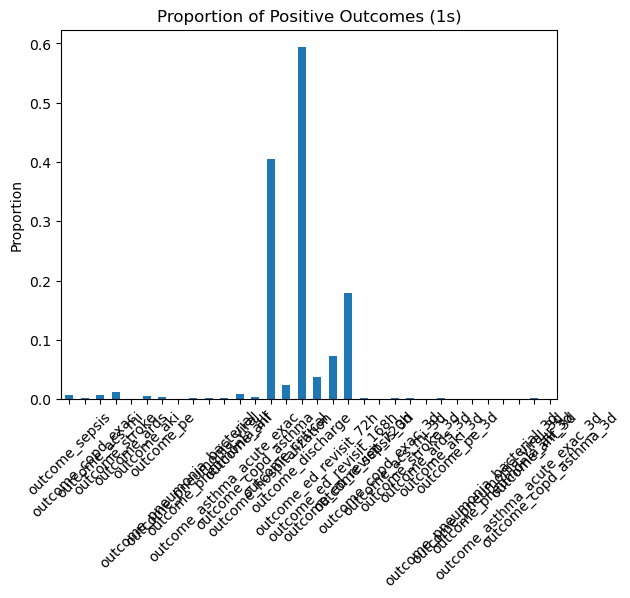

In [137]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. 筛选 outcome 列
outcome_cols = [col for col in visits.columns if col.startswith('outcome_')]

# 2. 计算比例
proportions = visits[outcome_cols].mean().round(4)

# 3. 打印结果
print("各 outcome 列的比例 (值为1的占比):")
print(proportions)

# 4. 可视化
proportions.plot(kind='bar', title='Proportion of Positive Outcomes (1s)')
plt.ylabel('Proportion')
plt.xticks(rotation=45)
plt.show()

In [136]:
visits.to_csv('cleaned_visits_with_outcome.csv', index=False)  # 不保存行索引